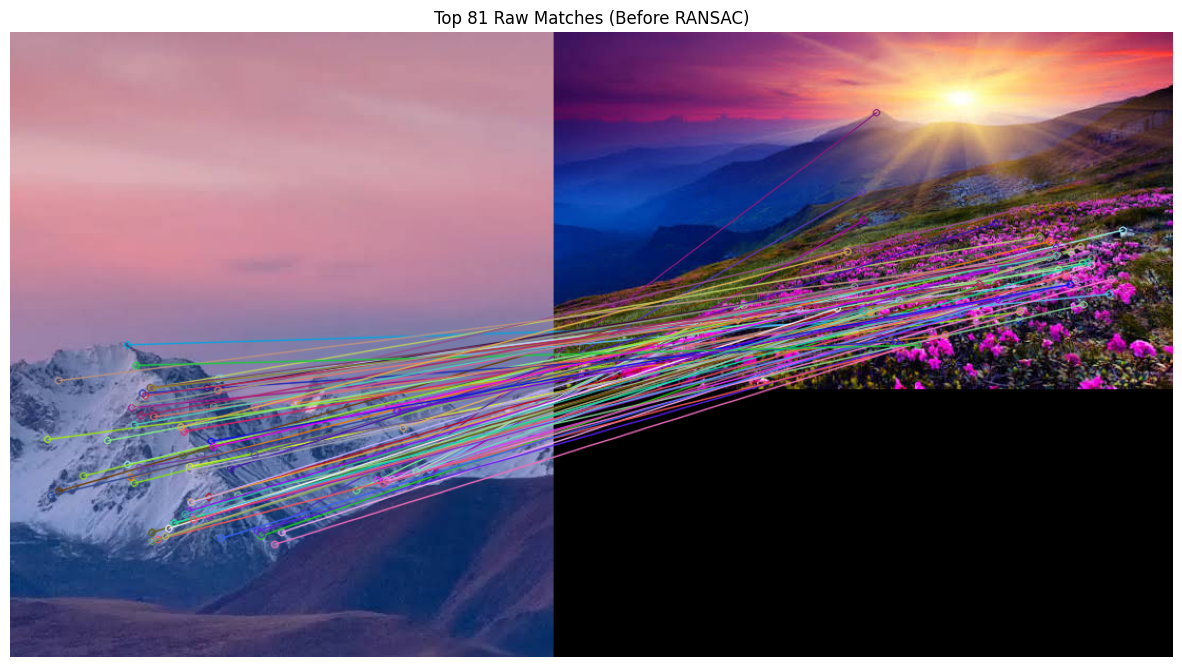

Total Matches: 81
Inliers found by RANSAC: 8
Homography Matrix:
[[ 1.63263529e-01 -1.24131713e+00  4.76612221e+02]
 [ 7.07110726e-02 -5.44243097e-01  2.09312246e+02]
 [ 3.37684300e-04 -2.60320613e-03  1.00000000e+00]]


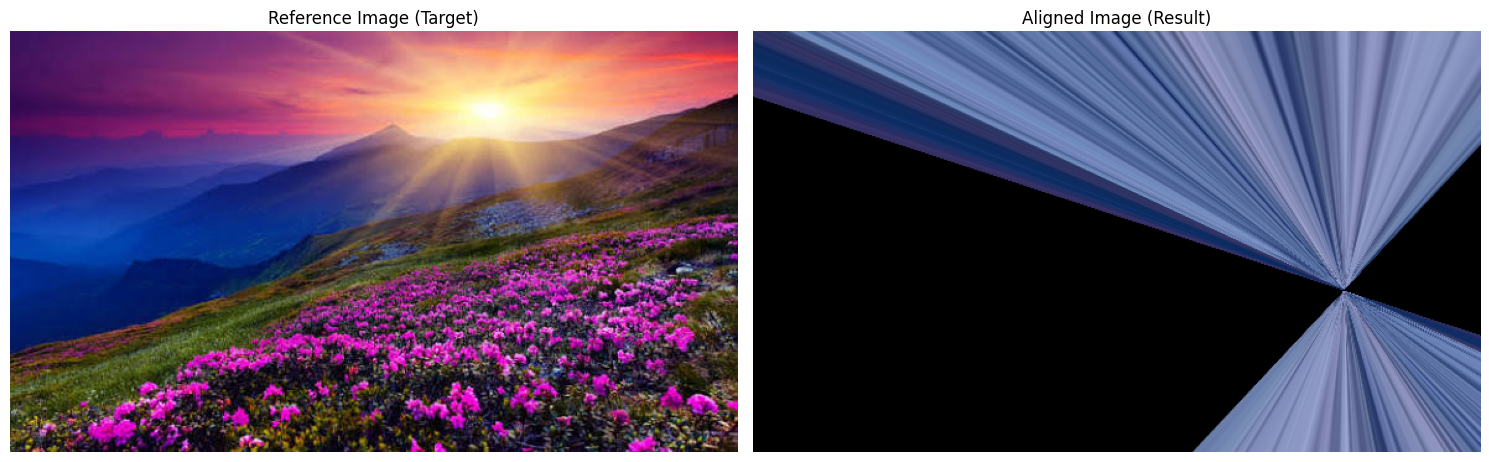

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


# 1. Load the Images
# Image to be aligned (Query Image)
img1 = cv2.imread('/content/drive/MyDrive/COMPUTER VISION/images013.jpg')

# Reference image (Target Image)
img2 = cv2.imread('/content/drive/MyDrive/COMPUTER VISION/images016.jpg')

# Check whether images are loaded successfully
if img1 is None or img2 is None:
    raise FileNotFoundError("Check the image filenames and paths.")


# 2. Convert Images to RGB for Display
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)


# 3. Convert Images to Grayscale
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)


# 4. Detect Features using ORB
# Initialize ORB detector
orb = cv2.ORB_create(nfeatures=2000)

# Detect keypoints and descriptors
keypoints1, descriptors1 = orb.detectAndCompute(gray1, None)
keypoints2, descriptors2 = orb.detectAndCompute(gray2, None)


# 5. Match Features using BFMatcher
# Hamming distance is used for ORB descriptors
bf = cv2.BFMatcher(
    cv2.NORM_HAMMING,
    crossCheck=True
)

# Match descriptors
if descriptors1 is None or descriptors2 is None:
    raise ValueError("Not enough features detected in the images.")

matches = bf.match(descriptors1, descriptors2)

# Sort matches based on distance
matches = sorted(matches, key=lambda x: x.distance)

# Select the top 15% matches
keep_percent = 0.15
num_keep = max(4, int(len(matches) * keep_percent))

best_matches = matches[:num_keep]

if len(best_matches) < 4:
    raise ValueError("At least 4 feature matches are required.")


# 6. Visualize Feature Matches (Before RANSAC)
img_matches = cv2.drawMatches(
    img1,
    keypoints1,
    img2,
    keypoints2,
    best_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
plt.title(f"Top {num_keep} Raw Matches (Before RANSAC)")
plt.axis('off')
plt.show()


# 7. Extract Matched Point Coordinates
points1 = np.zeros((len(best_matches), 2), dtype=np.float32)
points2 = np.zeros((len(best_matches), 2), dtype=np.float32)

for i, match in enumerate(best_matches):

    # Points from image to be aligned
    points1[i, :] = keypoints1[match.queryIdx].pt

    # Points from reference image
    points2[i, :] = keypoints2[match.trainIdx].pt


# 8. Compute Homography Matrix using RANSAC
h_matrix, mask = cv2.findHomography(
    points1,
    points2,
    cv2.RANSAC,
    5.0
)

if h_matrix is None or mask is None:
    raise ValueError("Homography calculation failed. Try different images.")


# Count RANSAC inliers
matches_mask = mask.ravel().tolist()
inliers_count = np.sum(matches_mask)

print("Total Matches:", len(best_matches))
print("Inliers found by RANSAC:", inliers_count)
print("Homography Matrix:")
print(h_matrix)


# 9. Apply Homography (Image Alignment)
height, width = img2.shape[:2]

aligned_img = cv2.warpPerspective(
    img1,
    h_matrix,
    (width, height)
)


# 10. Display Final Results
plt.figure(figsize=(15, 10))

# Reference Image
plt.subplot(1, 2, 1)
plt.imshow(img2_rgb)
plt.title("Reference Image (Target)")
plt.axis('off')

# Aligned Image
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(aligned_img, cv2.COLOR_BGR2RGB))
plt.title("Aligned Image (Result)")
plt.axis('off')

plt.tight_layout()
plt.show()